<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/21-responsible-and-production-ai/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Capstone: From Notebook to Service

This is the last project of the course, and it puts everything together. You'll take one model through the whole life it would have in a real organisation: from raw data, through a careful choice of model, an audit and explanations, to a documented, tested web service, and then into a simulated year and a half of use, where the world changes under it.

The problem is the one from the Module 13 mini project. Between May 2008 and November 2010, a Portuguese bank phoned customers to offer a **term deposit**, and recorded 41,188 of those calls with the customer's details and the answer. The bank wants a score that tells it whom to call. Module 13 showed how to evaluate such a score; this time the question is how to **ship** it and **keep it working**.

The story is set in July 2009. The bank has the calls made so far, wants a model in production, and will keep calling customers for the next eighteen months.

1. The data, as the bank has it in July 2009
2. Features in one shared file
3. Choosing a model, with every run tracked
4. A fairness audit by age group
5. Explaining the model
6. The model bundle and its model card
7. The web service and its tests
8. The container
9. Eighteen months in production: monitoring
10. Responding to an alert
11. The final checklist

Everything runs on a normal computer in a minute or two.

In [1]:
import hashlib
import importlib
import importlib.util
import itertools
import json
import math
import os
import platform
import subprocess
import sys
import time
from pathlib import Path

for package in ["fastapi", "httpx", "pytest"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import joblib
import numpy as np
import pandas as pd
import sklearn
from scipy import optimize, special
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/13-evaluating-classifiers/data/bank_marketing.csv.gz"
local = Path("../13-evaluating-classifiers/data/bank_marketing.csv.gz")
bank = pd.read_csv(local if local.exists() else DATA_URL)

WORK = Path("work/capstone")          # everything the service needs ends up in this folder
WORK.mkdir(parents=True, exist_ok=True)
print("scikit-learn", sklearn.__version__, "  pandas", pd.__version__)
print(bank.shape)

scikit-learn 1.9.1   pandas 3.0.5
(41188, 21)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. The data, as the bank has it in July 2009

The rows are in time order. As in Module 13, the year can be recovered from the months: whenever the month goes backwards, a new year has started. We also label each call with its quarter, because the bank will review its model every three months.

Then the two decisions that protect the whole project:

- **`duration` goes.** The length of a call is only known after the call, so it can't help decide whom to call. Module 13 showed how much it inflates the scores.
- **The split follows time.** The model is built from calls up to the end of June 2009. Everything after that is the future: the notebook only looks at it in Section 9, one quarter at a time, the way the bank would have seen it.

In [3]:
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_number = bank["month"].map({m: i for i, m in enumerate(MONTHS, start=1)})
bank["year"] = 2008 + (month_number.diff() < 0).cumsum()
bank["period"] = bank["year"].astype(str) + "-" + month_number.astype(str).str.zfill(2)
bank["quarter"] = bank["year"].astype(str) + "-Q" + ((month_number - 1) // 3 + 1).astype(str)
bank["subscribed"] = (bank["y"] == "yes").astype(int)
bank = bank.drop(columns=["duration", "y"])

history = bank[bank["period"] <= "2009-06"]          # what the bank knows in July 2009
future = bank[bank["period"] > "2009-06"]            # arrives later, quarter by quarter
cut = int(len(history) * 0.8)
development, validation = history.iloc[:cut], history.iloc[cut:]

for name, part in [("development", development), ("validation", validation), ("future", future)]:
    print(f"{name:12s} {len(part):6,} calls  {part['period'].iloc[0]} to {part['period'].iloc[-1]}  "
          f"subscribed {part['subscribed'].mean():.1%}")

development  29,551 calls  2008-05 to 2009-04  subscribed 5.6%
validation    7,388 calls  2009-04 to 2009-06  subscribed 13.9%
future        4,249 calls  2009-07 to 2010-11  subscribed 45.8%


The validation set is the most recent fifth of the history, so choosing a model on it mimics the real task: train on the past, predict what comes next. Notice that the subscription rate is not stable even within the history. It was around 5% in 2008 and much higher in spring 2009; in the future it rises further. Keep that in mind, because it comes back in Section 9.

## 2. Features in one shared file

A classic production bug is **training/serving skew**: the notebook prepares features one way, the web service another, and the model quietly receives inputs it was never trained on. The cure is to write the preparation **once**, in a small Python file that both the training code and the service import.

The `%%writefile` command at the top of the next cell saves the cell as a file instead of running it.

In [4]:
%%writefile work/capstone/features.py
"""Feature preparation shared by model training and the web service."""
import pandas as pd

CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "day_of_week", "poutcome"]
NUMERIC = ["age", "campaign", "previous", "contacted_before"]

# Columns that describe *when* a call was made rather than *who* was called.
CONTEXT_CATEGORICAL = ["month"]
CONTEXT_NUMERIC = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]


def prepare(raw: pd.DataFrame, context: bool = False) -> pd.DataFrame:
    """Turn raw call records into model inputs. `pdays` = 999 means never contacted before."""
    frame = raw.copy()
    frame["contacted_before"] = (frame["pdays"] != 999).astype(float)
    for column in ["age", "campaign", "previous"]:
        frame[column] = frame[column].astype(float)
    columns = CATEGORICAL + NUMERIC
    if context:
        columns = CATEGORICAL + CONTEXT_CATEGORICAL + NUMERIC + CONTEXT_NUMERIC
    return frame[columns]

Writing work/capstone/features.py


In [5]:
sys.path.insert(0, str(WORK))
import features

importlib.reload(features)          # pick up changes if you edit and rerun the cell above
print(features.prepare(history.head(3)).T)

                            0            1            2
job                 housemaid     services     services
marital               married      married      married
education            basic.4y  high.school  high.school
default                    no      unknown           no
housing                    no           no          yes
loan                       no           no           no
contact             telephone    telephone    telephone
day_of_week               mon          mon          mon
poutcome          nonexistent  nonexistent  nonexistent
age                      56.0         57.0         37.0
campaign                  1.0          1.0          1.0
previous                  0.0          0.0          0.0
contacted_before          0.0          0.0          0.0


`pdays` uses 999 for "never contacted", which Module 13 turned into a yes/no column; that rule now lives in one place. The file also lists the **context** columns, the month and five economic indicators. They describe when a call was made, not who was called, and Section 3 tests whether they help.

## 3. Choosing a model, with every run tracked

Every candidate gets the same treatment: train on the development data, score the validation data, and append one record to a run log (Section 10 of the lesson). Four candidates: logistic regression and gradient boosting, each with and without the context columns.

One more measurement matters here. The bank decides whom to call **within a month**: each month it has a list of customers and calls the most promising ones. So the useful skill is ranking customers called at the same time. A model can get a good ordinary AUC just by recognising that calls made in one month succeed more often than calls made in another, which doesn't help anyone choose whom to call. The **within-month AUC**, computed separately for each month and averaged (weighted by the number of calls), measures only the useful skill.

In [6]:
RUNS = WORK / "runs.jsonl"
RUNS.unlink(missing_ok=True)


def fingerprint(frame):
    return hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()[:16]


def auc_within_months(y, p, periods):
    """ROC AUC computed inside each month, averaged with weights equal to the number of calls."""
    frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "period": np.asarray(periods)})
    scores, weights = [], []
    for _, month in frame.groupby("period"):
        if month["y"].nunique() == 2:
            scores.append(roc_auc_score(month["y"], month["p"]))
            weights.append(len(month))
    return float(np.average(scores, weights=weights))


def make_logistic(categorical, numeric):
    encode = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
                                ("numbers", StandardScaler(), numeric)])
    return make_pipeline(encode, LogisticRegression(max_iter=3000))


def make_boosting(categorical, numeric):
    encode = ColumnTransformer([("categories", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)],
                               remainder="passthrough")
    model = HistGradientBoostingClassifier(categorical_features=list(range(len(categorical))), learning_rate=0.05,
                                           max_iter=200, random_state=0)
    return make_pipeline(encode, model)


def log_run(name, params, metrics, train_frame):
    record = {"run": name, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "params": params, "metrics": metrics,
              "train_data": fingerprint(train_frame),
              "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__}}
    with RUNS.open("a") as f:
        f.write(json.dumps(record) + "\n")


with_context = (features.CATEGORICAL + features.CONTEXT_CATEGORICAL, features.NUMERIC + features.CONTEXT_NUMERIC)
without_context = (features.CATEGORICAL, features.NUMERIC)
candidates = {
    "logistic, customer only": (make_logistic, without_context, False),
    "logistic, with context": (make_logistic, with_context, True),
    "boosting, customer only": (make_boosting, without_context, False),
    "boosting, with context": (make_boosting, with_context, True),
}
for name, (make, (categorical, numeric), context) in candidates.items():
    X_dev, X_val = features.prepare(development, context), features.prepare(validation, context)
    pipeline = make(categorical, numeric).fit(X_dev, development["subscribed"])
    p_val = pipeline.predict_proba(X_val)[:, 1]
    log_run(name, {"model": make.__name__, "context_columns": context},
            {"auc": round(roc_auc_score(validation["subscribed"], p_val), 4),
             "auc_within_months": round(auc_within_months(validation["subscribed"], p_val, validation["period"]), 4),
             "average_precision": round(average_precision_score(validation["subscribed"], p_val), 4)},
            X_dev.assign(y=development["subscribed"].to_numpy()))

runs = [json.loads(line) for line in RUNS.read_text().splitlines()]
print(pd.DataFrame([{"run": r["run"], **r["metrics"]} for r in runs]).set_index("run").to_string())

                            auc  auc_within_months  average_precision
run                                                                  
logistic, customer only  0.6383             0.6133             0.2317
logistic, with context   0.7079             0.6040             0.3137
boosting, customer only  0.6025             0.5816             0.2136
boosting, with context   0.6519             0.6037             0.2551


By the ordinary AUC, the context columns look like a big improvement: 0.708 against 0.638 for logistic regression, and average precision agrees. The within-month AUC tells a different story: 0.604 against 0.613, no better at all. The validation period covers April to June 2009, months whose subscription rates were very different, and the context columns let a model recognise the month. That lifts the pooled scores without helping the bank choose between two customers on the same list.

There are two more reasons to leave them out. In the training data, the economic indicators take only a handful of values, one per month or quarter, so all a model can do with them is memorise periods. And in production they move far outside anything seen in training (Section 9 shows the Euribor rate). Boosting doesn't beat logistic regression either: the signal is weak and mostly additive, so the extra flexibility mostly fits noise.

So the choice is the simplest candidate, which is also the easiest to explain: **logistic regression on the customer columns only**.

In [7]:
CHOSEN = "logistic, customer only"
model = make_logistic(features.CATEGORICAL, features.NUMERIC).fit(features.prepare(history), history["subscribed"])
X_val = features.prepare(validation)
p_val_dev = make_logistic(features.CATEGORICAL, features.NUMERIC).fit(features.prepare(development), development["subscribed"]).predict_proba(X_val)[:, 1]
print(f"chosen: {CHOSEN}, refitted on all {len(history):,} calls of the history")

chosen: logistic, customer only, refitted on all 36,939 calls of the history


After choosing, the model is refitted on the **whole** history, development and validation together, so it learns from the most recent calls too. The validation scores of the development-only fit (`p_val_dev`) stay as the honest estimate of how well this recipe works on unseen data, and the audit below uses them.

## 4. A fairness audit by age group

The bank's rule from Module 13 still applies: a call costs 5 and a new deposit is worth 40, so a call pays off when the probability of a yes is at least 5 / 40 = 0.125. Who gets called under that rule?

Age is the natural group to audit here. Older and younger customers subscribe at very different rates, and many countries' regulators pay special attention to how financial products are sold to older customers. Being called is mostly a small nuisance, and not being called means missing an offer, so the stakes are lower than in the lesson's income example. That's exactly the kind of judgement an audit should state, rather than leave implicit.

In [8]:
THRESHOLD = 5 / 40
AGE_GROUPS = pd.cut(bank["age"], [0, 29, 59, 200], labels=["under 30", "30 to 59", "60 and over"])


def group_report(y, call, groups):
    rows = {}
    for g in pd.unique(groups):
        mask = np.asarray(groups == g)
        t, c = np.asarray(y)[mask], np.asarray(call)[mask]
        rows[g] = {"calls": int(mask.sum()), "subscription rate": t.mean(), "share called": c.mean(),
                   "precision": t[c].mean() if c.any() else np.nan, "recall (TPR)": c[t == 1].mean() if (t == 1).any() else np.nan}
    return pd.DataFrame(rows).T.loc[["under 30", "30 to 59", "60 and over"]]


call_val = p_val_dev >= THRESHOLD
audit = group_report(validation["subscribed"], call_val, AGE_GROUPS.loc[validation.index])
print(audit.round(3).to_string())
print(f"\noverall: share called {call_val.mean():.3f}, precision {validation['subscribed'][call_val].mean():.3f}, "
      f"recall {call_val[validation['subscribed'] == 1].mean():.3f}")
print(f"average prediction {p_val_dev.mean():.3f}, actual subscription rate {validation['subscribed'].mean():.3f}")

              calls  subscription rate  share called  precision  recall (TPR)
under 30     1458.0              0.171         0.163      0.282         0.269
30 to 59     5790.0              0.126         0.041      0.383         0.123
60 and over   140.0              0.350         0.164      0.435         0.204

overall: share called 0.067, precision 0.337, recall 0.163
average prediction 0.074, actual subscription rate 0.139


Three things to read from this table.

- **Very few calls.** The model was trained on development data, where about 5.6% said yes, and its predictions average about that, while the validation months really ran at 13.9%. So few customers reach 0.125, and only about 7% are called. That's the first sign of a problem that Section 9 makes plain.
- **A large gap in recall.** A subscriber aged 30 to 59 has about a 12% chance of being called, against 27% under 30 and 20% for 60 and over. The model calls more often in the groups whose members say yes more often, and the middle group, most of the bank's customers, has the lowest rate.
- **A small group.** There are only 140 calls to people aged 60 and over in the validation period, so their numbers are uncertain.

Is the gap unfair? It follows real differences in how often each group said yes, and the harm of not being called is small, so the bank may reasonably accept it. But that's a decision to write down, with the numbers, where anyone can see and question it. The model card in Section 6 does exactly that.

## 5. Explaining the model

Two views, as in the lesson. **Permutation importance** on the validation data shows which columns the model relies on overall; a **Shapley explanation** shows why it scores one particular customer as it does.

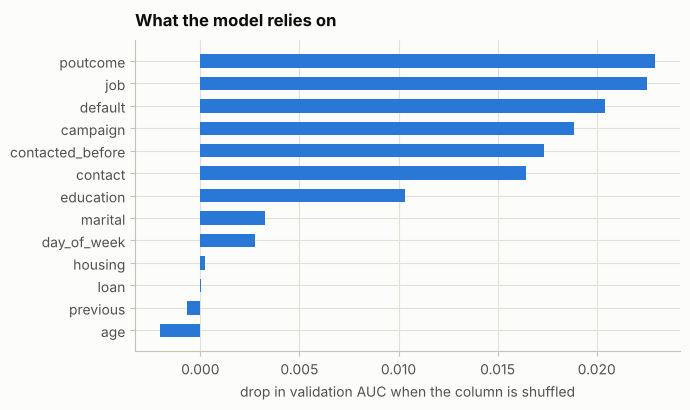

In [9]:
result = permutation_importance(model, X_val, validation["subscribed"], scoring="roc_auc", n_repeats=5, random_state=0)
importance = pd.Series(result.importances_mean, index=X_val.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=PALETTE[0], height=0.6)
ax.set_xlabel("drop in validation AUC when the column is shuffled")
ax.set_title("What the model relies on")
fig.tight_layout()
plt.show()

The outcome of the previous campaign (`poutcome`), the job, the credit default status and the number of calls in this campaign matter most. Age gets no importance at all, which looks surprising, since students and retired people subscribe much more often. There are two reasons. A logistic regression treats age as a straight line, but the age effect is U-shaped (the young and the old both subscribe more), and a straight line can't follow that. And `job` already carries most of the information, with categories such as student and retired. That's the proxy effect from the lesson, harmless here, and a reminder that a column with zero importance doesn't mean the model ignores what that column stands for.

For one customer, the Shapley values below use the exact method from the lesson. With 13 columns there are 8,192 subsets, still quick for a logistic regression.

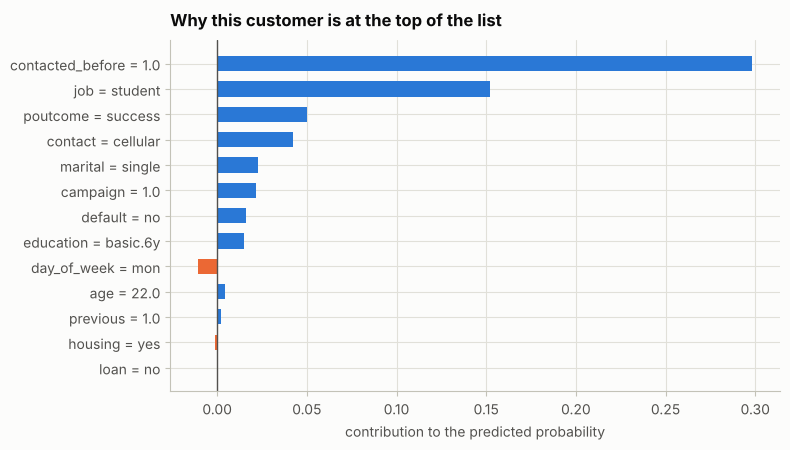

average prediction 0.074 + contributions +0.614 = 0.688   (model: 0.688)


In [10]:
def shapley_values(predict, row, background):
    """Exact interventional Shapley values for one row (a DataFrame with one row)."""
    columns = list(row.columns)
    d = len(columns)
    subsets = [s for size in range(d + 1) for s in itertools.combinations(range(d), size)]
    frames = []
    for subset in subsets:
        mixed = background.copy()
        for j in subset:
            mixed[columns[j]] = row.iloc[0, j]
        frames.append(mixed)
    predictions = predict(pd.concat(frames, ignore_index=True)).reshape(len(subsets), len(background))
    value = dict(zip(subsets, predictions.mean(axis=1)))
    phi = np.zeros(d)
    for j in range(d):
        for size in range(d):
            weight = math.factorial(size) * math.factorial(d - size - 1) / math.factorial(d)
            for subset in itertools.combinations([i for i in range(d) if i != j], size):
                phi[j] += weight * (value[tuple(sorted(subset + (j,)))] - value[subset])
    return pd.Series(phi, index=columns), value[()]


p_val_final = model.predict_proba(X_val)[:, 1]
customer = X_val.iloc[[int(np.argmax(p_val_final))]]
background = features.prepare(history).sample(50, random_state=0)
phi, base_value = shapley_values(lambda data: model.predict_proba(data)[:, 1], customer, background)

order = phi.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([f"{c} = {customer.iloc[0][c]}" for c in order], phi[order],
        color=[PALETTE[0] if v > 0 else PALETTE[1] for v in phi[order]], height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("contribution to the predicted probability")
ax.set_title("Why this customer is at the top of the list")
fig.tight_layout()
plt.show()
print(f"average prediction {base_value:.3f} + contributions {phi.sum():+.3f} = {base_value + phi.sum():.3f}"
      f"   (model: {model.predict_proba(customer)[0, 1]:.3f})")

This customer is a 22-year-old student who was contacted in an earlier campaign and said yes then. Having been contacted before contributes the most, then being a student, then the earlier success; together they lift the prediction from about 7% for an average customer to about 69%. The contributions add up exactly to the model's prediction. An explanation like this is something a call-centre manager, or a customer asking "why did you call me?", can actually use.

## 6. The model bundle and its model card

The bundle holds everything the service needs: the pipeline, the allowed values of every category (taken from the training data, so the service can reject anything else), the decision threshold, a version number, and where the model came from. The model card is written from the same numbers, so it can't drift away from the notebook.

In [11]:
history_inputs = features.prepare(history)
bundle = {
    "pipeline": model,
    "version": "1.0",
    "threshold": THRESHOLD,
    "categories": {c: sorted(history_inputs[c].unique().tolist()) for c in features.CATEGORICAL},
    "trained_on": f"{len(history):,} calls, {history['period'].iloc[0]} to {history['period'].iloc[-1]}",
    "train_data": fingerprint(history_inputs.assign(y=history["subscribed"].to_numpy())),
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
joblib.dump(bundle, WORK / "model.joblib")
chosen_run = next(r for r in runs if r["run"] == CHOSEN)["metrics"]

card = f"""# Model card: call-list model, version {bundle['version']}

**What it does.** Estimates the probability that a customer agrees to open a term deposit if the bank calls them,
from 13 facts about the customer and their contact history. The bank calls a customer when the probability is at
least {THRESHOLD} (a call costs 5, a deposit is worth 40).

**Intended use.** Ordering the bank's monthly call lists. **Not** for decisions about credit, pricing or any product
other than term deposits, and not for customers outside the bank's existing customer base.

**Training data.** {bundle['trained_on']} (fingerprint {bundle['train_data']}). The call length (`duration`) is excluded
because it is only known after the call. The month and economic indicators are excluded: they describe when a call
was made, and they did not improve ranking within a month on validation data.

**Evaluation (validation: the most recent fifth of the history, model trained on the rest).**
AUC {chosen_run['auc']:.3f}, within-month AUC {chosen_run['auc_within_months']:.3f}, average precision {chosen_run['average_precision']:.3f}.

**By age group (validation, threshold {THRESHOLD}).**

| group | calls | subscription rate | share called | precision | recall |
|---|---|---|---|---|---|
""" + "\n".join(f"| {g} | {int(r['calls'])} | {r['subscription rate']:.3f} | {r['share called']:.3f} | {r['precision']:.3f} | {r['recall (TPR)']:.3f} |"
                for g, r in audit.iterrows()) + f"""

**Known limitations.** The ranking is modest (AUC around {chosen_run['auc']:.2f}). Probabilities are calibrated to the
subscription rates of 2008 and early 2009, which changed a lot over time. Customers over 60 are few in the data.

**Monitoring plan.** Every quarter: population stability index (PSI) of the inputs and of the predictions (alert above
0.25); when outcomes arrive, the gap between the average prediction and the actual rate (alert above 0.10) and
the within-month AUC (alert below {chosen_run['auc_within_months'] - 0.05:.2f}). Alerts go to the model owner, who decides
whether to recalibrate, retrain or roll back.
"""
(WORK / "model_card.md").write_text(card)
print(card)

# Model card: call-list model, version 1.0

**What it does.** Estimates the probability that a customer agrees to open a term deposit if the bank calls them,
from 13 facts about the customer and their contact history. The bank calls a customer when the probability is at
least 0.125 (a call costs 5, a deposit is worth 40).

**Intended use.** Ordering the bank's monthly call lists. **Not** for decisions about credit, pricing or any product
other than term deposits, and not for customers outside the bank's existing customer base.

**Training data.** 36,939 calls, 2008-05 to 2009-06 (fingerprint d3a6441e3cda591c). The call length (`duration`) is excluded
because it is only known after the call. The month and economic indicators are excluded: they describe when a call
was made, and they did not improve ranking within a month on validation data.

**Evaluation (validation: the most recent fifth of the history, model trained on the rest).**
AUC 0.638, within-month AUC 0.613, average precision 

## 7. The web service and its tests

The service is a real file, `app.py`, that imports the same `prepare` function as the notebook. It reads the model's location from an environment variable, which is how containers are usually configured. Three habits from the lesson are built in:

- `pydantic` checks every field's type and range, and `extra="forbid"` rejects fields the model doesn't expect. A client that sends `duration` gets an error instead of a silent leak.
- Category values are checked against the ones seen in training.
- The response says which model version produced it, so every decision can be traced back to a model card.

In [12]:
%%writefile work/capstone/app.py
"""Web service for the call-list model. Start it with: uvicorn app:app"""
import os

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict, Field

from features import prepare


class Customer(BaseModel):
    model_config = ConfigDict(extra="forbid")
    age: int = Field(ge=17, le=100)
    job: str
    marital: str
    education: str
    default: str
    housing: str
    loan: str
    contact: str
    day_of_week: str
    poutcome: str
    campaign: int = Field(ge=1, le=100)
    pdays: int = Field(ge=0, le=999)
    previous: int = Field(ge=0, le=100)


def create_app(bundle):
    app = FastAPI(title="Call-list model")

    @app.get("/health")
    def health():
        return {"status": "ok", "version": bundle["version"], "trained_on": bundle["trained_on"]}

    @app.post("/score")
    def score(customer: Customer):
        row = customer.model_dump()
        for column, allowed in bundle["categories"].items():
            if row[column] not in allowed:
                raise HTTPException(status_code=422, detail=f"unknown {column}: {row[column]!r}")
        probability = float(bundle["pipeline"].predict_proba(prepare(pd.DataFrame([row])))[0, 1])
        return {"probability": round(probability, 4), "call": probability >= bundle["threshold"],
                "model_version": bundle["version"]}

    return app


app = create_app(joblib.load(os.environ.get("MODEL_PATH", "model.joblib")))

Writing work/capstone/app.py


The tests go in their own file too, so they can run automatically whenever the code changes. They're written for **pytest**, the standard Python test runner (Module 10): every function whose name starts with `test_` is a test, and a failed `assert` fails it.

In [13]:
%%writefile work/capstone/test_app.py
import os

import joblib
import pandas as pd
from fastapi.testclient import TestClient

from app import app
from features import prepare

client = TestClient(app)
bundle = joblib.load(os.environ.get("MODEL_PATH", "model.joblib"))
CUSTOMER = {"age": 35, "job": "admin.", "marital": "single", "education": "university.degree", "default": "no",
            "housing": "yes", "loan": "no", "contact": "cellular", "day_of_week": "thu", "poutcome": "success",
            "campaign": 1, "pdays": 6, "previous": 1}


def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["version"] == bundle["version"]


def test_score_matches_the_model():
    response = client.post("/score", json=CUSTOMER)
    assert response.status_code == 200
    expected = bundle["pipeline"].predict_proba(prepare(pd.DataFrame([CUSTOMER])))[0, 1]
    assert abs(response.json()["probability"] - expected) < 1e-4
    assert response.json()["call"] == (expected >= bundle["threshold"])


def test_rejects_age_out_of_range():
    assert client.post("/score", json={**CUSTOMER, "age": 300}).status_code == 422


def test_rejects_unknown_category():
    assert client.post("/score", json={**CUSTOMER, "job": "astronaut"}).status_code == 422


def test_rejects_missing_field():
    assert client.post("/score", json={k: v for k, v in CUSTOMER.items() if k != "pdays"}).status_code == 422


def test_rejects_leaking_field():
    assert client.post("/score", json={**CUSTOMER, "duration": 300}).status_code == 422

Writing work/capstone/test_app.py


In [14]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "-W", "ignore::DeprecationWarning", "test_app.py"], cwd=WORK,
                        env={**os.environ, "MODEL_PATH": "model.joblib"}, capture_output=True, text=True)
print(result.stdout[-600:])
tests_passed = result.returncode == 0

......                                                                   [100%]
6 passed in 1.34s



Six tests, all passing. `test_score_matches_the_model` is the one that catches training/serving skew: the service's answer must equal the notebook's for the same customer. On your own computer, `pytest` in the `work/capstone` folder runs the same tests.

You can also call the service from the notebook, exactly as a client would:

In [15]:
os.environ["MODEL_PATH"] = str(WORK / "model.joblib")
from fastapi.testclient import TestClient
import app as service

importlib.reload(service)
client = TestClient(service.app)
example = {"age": 35, "job": "admin.", "marital": "single", "education": "university.degree", "default": "no",
           "housing": "yes", "loan": "no", "contact": "cellular", "day_of_week": "thu", "poutcome": "success",
           "campaign": 1, "pdays": 6, "previous": 1}
print(client.get("/health").json())
print(client.post("/score", json=example).json())
print(client.post("/score", json={**example, "poutcome": "nonexistent", "pdays": 999, "previous": 0}).json())
print(client.post("/score", json={**example, "duration": 300}).json()["detail"][0]["msg"])

{'status': 'ok', 'version': '1.0', 'trained_on': '36,939 calls, 2008-05 to 2009-06'}
{'probability': 0.4982, 'call': True, 'model_version': '1.0'}
{'probability': 0.1314, 'call': True, 'model_version': '1.0'}
Extra inputs are not permitted


The same customer, once with a successful previous campaign and once never contacted before, gets very different scores, matching what the explanations showed.

## 8. The container

The last step before deployment is a container image with the code, the model and pinned library versions. These are the files it needs:

In [16]:
dockerfile = """FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY features.py app.py model.joblib ./
ENV MODEL_PATH=model.joblib
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
"""
requirements = f"scikit-learn=={sklearn.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\nfastapi\nuvicorn\njoblib\n"
(WORK / "Dockerfile").write_text(dockerfile)
(WORK / "requirements.txt").write_text(requirements)
print(sorted(p.name for p in WORK.iterdir() if p.is_file()))

['Dockerfile', 'app.py', 'features.py', 'model.joblib', 'model_card.md', 'requirements.txt', 'runs.jsonl', 'test_app.py']


With Docker installed, `docker build -t call-list .` and then `docker run -p 8000:8000 call-list` in that folder start the service, and http://localhost:8000/docs shows FastAPI's interactive page for trying it. The folder now holds a complete, reproducible deployment: code, model, tests, model card, run log and container recipe.

## 9. Eighteen months in production: monitoring

The model goes live in July 2009. Every quarter, the bank reviews two kinds of evidence:

- **Without labels**, available immediately: are the inputs and the predictions still distributed as in training? PSI for the main numeric columns, PSI on category shares for the categorical ones, and PSI of the predictions. The Euribor interest rate isn't a model input, but it's watched as a sign of how much the world has changed.
- **With labels**, available once the calls are done: the gap between the average prediction and the actual subscription rate, the within-month AUC, and the profit of the calls made.

In [17]:
def psi(expected, actual, edges=None, bins=10):
    expected, actual = np.asarray(expected, dtype=float), np.asarray(actual, dtype=float)
    if edges is None:
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges = np.array(edges, dtype=float)
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-4, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))


def psi_categories(expected, actual):
    categories = sorted(set(expected) | set(actual))
    e = np.clip(pd.Series(expected).value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy(), 1e-4, None)
    a = np.clip(pd.Series(actual).value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy(), 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))


def profit(y, call):
    return 40 * int(np.sum(np.asarray(y)[call])) - 5 * int(np.sum(call))


EDGES = {"age": None, "campaign": [-np.inf, 1.5, 2.5, 3.5, 5.5, np.inf], "previous": [-np.inf, 0.5, 1.5, np.inf]}
p_history = model.predict_proba(history_inputs)[:, 1]
ALERTS = {"input PSI": 0.25, "prediction PSI": 0.25, "calibration gap": 0.10,
          "within-month AUC": chosen_run["auc_within_months"] - 0.05}


def review(batch, predict):
    inputs = features.prepare(batch)
    p = predict(inputs)
    call = p >= THRESHOLD
    row = {"calls": len(batch)}
    for column, edges in EDGES.items():
        row[f"PSI {column}"] = psi(history_inputs[column], inputs[column], edges)
    for column in ["job", "poutcome"]:
        row[f"PSI {column}"] = psi_categories(history_inputs[column], inputs[column])
    row["PSI euribor3m"] = psi(history["euribor3m"], batch["euribor3m"])
    row["PSI prediction"] = psi(p_history, p)
    row["mean prediction"] = p.mean()
    row["actual rate"] = batch["subscribed"].mean()                       # known only after the quarter's calls
    row["calibration gap"] = row["actual rate"] - row["mean prediction"]
    row["within-month AUC"] = auc_within_months(batch["subscribed"], p, batch["period"])
    row["share called"] = call.mean()
    row["profit"] = profit(batch["subscribed"], call)
    row["profit, call everyone"] = profit(batch["subscribed"], np.ones(len(batch), dtype=bool))
    return row


frozen = lambda inputs: model.predict_proba(inputs)[:, 1]
monitor = pd.DataFrame({q: review(batch, frozen) for q, batch in future.groupby("quarter")}).T
input_columns = [c for c in monitor.columns if c.startswith("PSI")]
print(monitor[["calls"] + input_columns].astype(float).round(2).to_string())

          calls  PSI age  PSI campaign  PSI previous  PSI job  PSI poutcome  PSI euribor3m  PSI prediction
2009-Q3  1215.0     0.34          0.18          0.61     0.83          0.70           8.51            1.42
2009-Q4   976.0     0.47          0.19          0.96     0.77          1.01           8.51            1.35
2010-Q1   264.0     0.47          0.11          1.66     0.46          1.68           8.51            1.23
2010-Q2   615.0     0.31          0.11          1.74     0.71          1.66           8.51            1.24
2010-Q3   847.0     0.36          0.09          1.87     0.72          1.70           8.51            1.36
2010-Q4   332.0     0.39          0.23          2.15     0.72          1.86           8.51            1.76


In [18]:
print(monitor[["mean prediction", "actual rate", "calibration gap", "within-month AUC", "share called",
               "profit", "profit, call everyone"]].astype(float).round(3).to_string())


def alerts_for(row):
    found = [c for c in input_columns if c != "PSI euribor3m" and row[c] > ALERTS["input PSI"]]
    if abs(row["calibration gap"]) > ALERTS["calibration gap"]:
        found.append("calibration gap")
    if row["within-month AUC"] < ALERTS["within-month AUC"]:
        found.append("within-month AUC")
    return found


print()
for quarter, row in monitor.iterrows():
    print(f"{quarter}: {', '.join(alerts_for(row)) or 'no alerts'}")

         mean prediction  actual rate  calibration gap  within-month AUC  share called  profit  profit, call everyone
2009-Q3            0.169        0.359            0.190             0.600         0.395  6120.0                11365.0
2009-Q4            0.182        0.447            0.265             0.638         0.414  7300.0                12560.0
2010-Q1            0.206        0.568            0.362             0.690         0.413  2535.0                 4680.0
2010-Q2            0.217        0.530            0.313             0.686         0.481  6480.0                 9965.0
2010-Q3            0.219        0.527            0.307             0.742         0.466  8985.0                13605.0
2010-Q4            0.225        0.455            0.229             0.695         0.521  3135.0                 4380.0

2009-Q3: PSI age, PSI previous, PSI job, PSI poutcome, PSI prediction, calibration gap
2009-Q4: PSI age, PSI previous, PSI job, PSI poutcome, PSI prediction, calibration gap

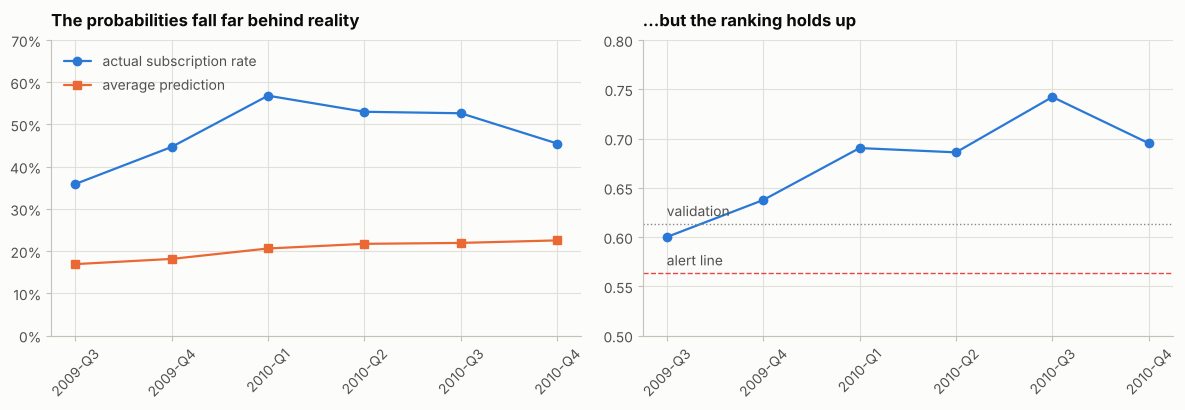

In [19]:
quarters = list(monitor.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(quarters, monitor["actual rate"].astype(float), color=PALETTE[0], marker="o", label="actual subscription rate")
axes[0].plot(quarters, monitor["mean prediction"].astype(float), color=PALETTE[1], marker="s", label="average prediction")
axes[0].set_ylim(0, 0.7)
axes[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[0].set_title("The probabilities fall far behind reality")
axes[0].legend(loc="upper left")
axes[1].plot(quarters, monitor["within-month AUC"].astype(float), color=PALETTE[0], marker="o", label="within-month AUC")
axes[1].axhline(chosen_run["auc_within_months"], color=MUTED, linestyle=":", linewidth=1)
axes[1].text(0, chosen_run["auc_within_months"] + 0.008, "validation", color=INK_2)
axes[1].axhline(ALERTS["within-month AUC"], color=PALETTE[7], linestyle="--", linewidth=1)
axes[1].text(0, ALERTS["within-month AUC"] + 0.008, "alert line", color=INK_2)
axes[1].set_ylim(0.5, 0.8)
axes[1].set_title("...but the ranking holds up")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

Read the tables from the top.

**Inputs.** Almost everything alerts from the very first quarter. The calls of 2009 and 2010 went to a different population: far more customers from earlier campaigns (`previous`, `poutcome`), more older customers, and a different mix of jobs. Part of that is the bank's own doing: once earlier campaigns exist, more calls go to the people from them. The Euribor PSI is off the scale, because interest rates in production are lower than anything in most of the training period. **The predictions** shift too, since the inputs did.

**Outcomes.** When the labels arrive, the picture is clear. The model predicts around 20% while about half of the customers say yes: a calibration gap of 0.19 to 0.36, far over the 0.10 alert line. But the **within-month AUC never alerts**. The model still orders customers well, even a little better than on validation, perhaps because more customers now have a contact history, its strongest signal.

The calibration gap is expensive. The rule "call if the probability is at least 0.125" assumes the probabilities are right. With predictions far too low, the bank skips many calls that would have paid off, and in every quarter simply calling everyone would have made more profit than following the model. Input drift alone couldn't say whether the drift mattered; the outcomes could.

## 10. Responding to an alert

The monitoring has done its job: it says **what** broke. The ranking still works, so the model doesn't need replacing; its probabilities are too low, because the share of customers who say yes has risen. Three candidate responses, each tried quarter by quarter using only the labels available at the time:

- **Do nothing** (the frozen model).
- **Recalibrate**: keep the model, but shift all its log-odds by one number chosen so that, on the most recent quarter with known outcomes, the average prediction equals the actual rate. This keeps the ranking exactly and costs one line of code.
- **Retrain** on all the labelled calls so far.

In [20]:
def recalibration_shift(p, y):
    """The shift in log-odds that makes the average prediction equal the actual rate."""
    logits = special.logit(np.clip(p, 1e-6, 1 - 1e-6))
    return optimize.brentq(lambda s: special.expit(logits + s).mean() - np.mean(y), -10, 10)


rows = []
for quarter, batch in future.groupby("quarter"):
    labelled = bank[bank["quarter"] < quarter]                     # every call whose outcome is known by now
    latest = labelled[labelled["quarter"] == labelled["quarter"].iloc[-1]]
    shift = recalibration_shift(frozen(features.prepare(latest)), latest["subscribed"])
    retrained = make_logistic(features.CATEGORICAL, features.NUMERIC).fit(features.prepare(labelled), labelled["subscribed"])
    inputs, y = features.prepare(batch), batch["subscribed"].to_numpy()
    for name, p in [("do nothing", frozen(inputs)),
                    ("recalibrate", special.expit(special.logit(frozen(inputs)) + shift)),
                    ("retrain", retrained.predict_proba(inputs)[:, 1])]:
        rows.append({"quarter": quarter, "response": name, "calibration gap": y.mean() - p.mean(),
                     "within-month AUC": auc_within_months(y, p, batch["period"]),
                     "share called": (p >= THRESHOLD).mean(), "profit": profit(y, p >= THRESHOLD)})
responses = pd.DataFrame(rows)
print(responses.pivot(index="quarter", columns="response", values="calibration gap").round(3).to_string(), "\n")
print(responses.groupby("response")[["within-month AUC", "share called"]].mean().round(3).to_string(), "\n")
print("total profit:", responses.groupby("response")["profit"].sum().to_dict(),
      "  calling everyone:", int(monitor["profit, call everyone"].sum()))

response  do nothing  recalibrate  retrain
quarter                                   
2009-Q3        0.190        0.135    0.190
2009-Q4        0.265        0.074    0.236
2010-Q1        0.362        0.097    0.298
2010-Q2        0.313       -0.049    0.224
2010-Q3        0.307       -0.006    0.205
2010-Q4        0.229       -0.093    0.102 

             within-month AUC  share called
response                                   
do nothing              0.675         0.448
recalibrate             0.675         0.951
retrain                 0.660         0.600 

total profit: {'do nothing': 34555, 'recalibrate': 54250, 'retrain': 40315}   calling everyone: 56555


**Recalibration** fixes most of the problem. It lags a quarter behind, because it's tuned on the previous quarter's outcomes, but after the first quarter its gap stays within 0.1 of reality, against 0.19 to 0.36 for the frozen model. The ranking is untouched (the within-month AUC is identical), and the share of customers called rises to about 95%, which is right: when half of all customers say yes, almost every call pays for itself. Total profit rises from about 34,600 to about 54,300, close to the 56,600 that calling everyone would have made.

**Retraining** on all labelled calls helps much less. The 37,000 calls from the old period outweigh the few thousand new ones, so its probabilities stay too low (a gap of 0.10 to 0.30), and its ranking is no better.

The general lesson: diagnose first, then choose the cheapest response that fixes what broke. And notice what recalibration reveals about the business. With a subscription rate near 50%, the model adds little to the yes or no decision, because nearly everyone is worth calling; its value moves to **ordering** the list, which matters when the call centre can't reach everyone. A good monitoring review says that out loud instead of defending the model.

The same monitoring keeps an eye on fairness. Here is the age-group audit again, over all eighteen months, for the frozen and the recalibrated model:

In [21]:
shifts = {}
for quarter in future["quarter"].unique():
    labelled = bank[bank["quarter"] < quarter]
    latest = labelled[labelled["quarter"] == labelled["quarter"].iloc[-1]]
    shifts[quarter] = recalibration_shift(frozen(features.prepare(latest)), latest["subscribed"])
p_future = frozen(features.prepare(future))
p_recalibrated = special.expit(special.logit(p_future) + future["quarter"].map(shifts).to_numpy())
for name, p in [("do nothing", p_future), ("recalibrate", p_recalibrated)]:
    print(name)
    print(group_report(future["subscribed"], p >= THRESHOLD, AGE_GROUPS.loc[future.index]).round(3).to_string(), "\n")

do nothing
              calls  subscription rate  share called  precision  recall (TPR)
under 30      916.0              0.460         0.579      0.540         0.679
30 to 59     2535.0              0.452         0.319      0.655         0.462
60 and over   798.0              0.474         0.650      0.541         0.743 

recalibrate
              calls  subscription rate  share called  precision  recall (TPR)
under 30      916.0              0.460         0.976      0.461         0.979
30 to 59     2535.0              0.452         0.890      0.473         0.931
60 and over   798.0              0.474         0.944      0.485         0.966 



With the frozen model, the validation pattern persists: a subscriber aged 30 to 59 is called 46% of the time, against 68% under 30 and 74% for 60 and over. Yet by now all three groups subscribe at almost the same rate, 45 to 47%, so the gap no longer reflects any difference in behaviour; it's left over from the old data. Recalibration nearly closes it (93 to 98%), simply because almost everyone is called. A fairness audit at deployment is a snapshot; like accuracy, it has to be repeated on live data.

## 11. The final checklist

A deployment review usually ends with a checklist. Here it is as code, so it can't be ticked by accident:

In [22]:
card_text = (WORK / "model_card.md").read_text()
checklist = {
    "no column that is only known after the call": "duration" not in bank.columns,
    "split by time, future never used for choices": history["period"].max() < future["period"].min(),
    "every candidate run logged with a data fingerprint": len(runs) == len(candidates) and all("train_data" in r for r in runs),
    "features prepared by one shared function": (WORK / "features.py").exists() and "from features import prepare" in (WORK / "app.py").read_text(),
    "fairness audit in the model card": "By age group" in card_text,
    "intended and non-intended uses stated": "Intended use" in card_text and "**Not**" in card_text,
    "monitoring plan with thresholds": "Monitoring plan" in card_text and "alert" in card_text,
    "service rejects invalid and leaking inputs (tests pass)": tests_passed,
    "container recipe with pinned versions": f"scikit-learn=={sklearn.__version__}" in (WORK / "requirements.txt").read_text(),
    "alerts reviewed and a response chosen": len(responses) > 0,
}
for item, done in checklist.items():
    print(f"[{'x' if done else ' '}] {item}")
print(f"\n{sum(checklist.values())} of {len(checklist)} done")

[x] no column that is only known after the call
[x] split by time, future never used for choices
[x] every candidate run logged with a data fingerprint
[x] features prepared by one shared function
[x] fairness audit in the model card
[x] intended and non-intended uses stated
[x] monitoring plan with thresholds
[x] service rejects invalid and leaking inputs (tests pass)
[x] container recipe with pinned versions
[x] alerts reviewed and a response chosen

10 of 10 done


## What we learned

- **Evaluate the decision you'll actually make.** The ordinary AUC preferred models that recognised the month; the within-month AUC showed they ranked customers no better, and the simpler model won.
- **Write feature code once** and import it everywhere. The test that compares the service's answer with the notebook's is the cheapest protection against training/serving skew.
- **A model card is generated, not typed**, from the same numbers as the evaluation, and it states the intended use, the audit and the monitoring plan.
- **Validate inputs at the door**: types, ranges, known categories, and no unexpected fields.
- **Monitoring tells you what broke.** Here the ranking survived and the probabilities didn't, so the right response was a cheap recalibration, not a new model.
- **Fairness is monitored too**, because a model that was fair on validation data can drift like anything else.

**Try next:**

- Change the decision rule to "call the top 30% of each month's list" instead of a probability threshold. Does it need recalibration at all?
- Recalibrate per age group instead of with one shift, and compare the audit.
- Retrain on a sliding window (only the most recent 4,000 calls) and compare it with the three responses above.
- Add a `/score_batch` endpoint that takes a list of customers, with a test that it agrees with `/score`.
- Install Docker and run the container for real, then call it with `curl` or the `/docs` page.

# The end of the course

You started with `print("Hello")`. Twenty-one modules later you can clean and explore data, build and evaluate models from linear regression to transformers, train neural networks for images and text, use and adapt language models, and ship a model as a tested, documented, monitored service while asking who it might fail. That's the full arc of the work machine learning engineers and data scientists do.

A few ways to keep going, all free:

- **Practise on real problems.** Pick a public dataset you care about and take it through the checklist above. Competitions and datasets on [Kaggle](https://www.kaggle.com/) are a good source.
- **Go deeper.** The [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html) and the [PyTorch tutorials](https://pytorch.org/tutorials/) are excellent references. [Fairness and Machine Learning](https://fairmlbook.org/) by Barocas, Hardt and Narayanan and [Interpretable Machine Learning](https://christophm.github.io/interpretable-ml-book/) by Christoph Molnar are free books on the topics of this module.
- **Read papers with code.** Most of the methods in Modules 17 to 21 come from papers that are free to read on [arXiv](https://arxiv.org/).
- **Teach someone.** Explaining a notebook to a friend is the fastest way to find out what you really understand.

This course is free so that anyone, anywhere, can learn machine learning. If it helped you, share it with someone who might benefit, and if you find a mistake or have an idea, open an issue on the repository. Thank you for learning with it.